In [1]:
import numpy as np
import matplotlib.pyplot as plt


def infer_box2_from_box1(box1_coords, pattern_height):
    (y_min, y_max), (x_min, x_max) = box1_coords
    box2_y_min = pattern_height - y_max
    box2_y_max = pattern_height - y_min
    return ((box2_y_min, box2_y_max), (x_min, x_max))


def calculate_box_asymmetry_score(diffraction_pattern, box1_coords, box2_coords):
    """
    Calculate asymmetry score using masked center of mass approach.
    Each box COM is computed separately; the midpoint y-displacement from
    the pattern centre is returned as a percentage of pattern height.
    """
    if hasattr(diffraction_pattern, 'array'):
        pattern = np.array(diffraction_pattern.array)
    else:
        pattern = np.array(diffraction_pattern)
    pattern = np.asarray(pattern, dtype=np.float64)
    if pattern.ndim > 2:
        pattern = np.squeeze(pattern)

    ny, nx = pattern.shape

    def parse_coords(coords):
        (y_min, y_max), (x_min, x_max) = coords
        if 0 <= y_min <= 1 and 0 <= y_max <= 1:
            y_min, y_max = int(y_min * ny), int(y_max * ny)
        if 0 <= x_min <= 1 and 0 <= x_max <= 1:
            x_min, x_max = int(x_min * nx), int(x_max * nx)
        y_min = max(0, min(int(y_min), ny - 1))
        y_max = max(0, min(int(y_max), ny))
        x_min = max(0, min(int(x_min), nx - 1))
        x_max = max(0, min(int(x_max), nx))
        return y_min, y_max, x_min, x_max

    y1_min, y1_max, x1_min, x1_max = parse_coords(box1_coords)
    y2_min, y2_max, x2_min, x2_max = parse_coords(box2_coords)

    mask1 = np.zeros((ny, nx), dtype=bool)
    mask2 = np.zeros((ny, nx), dtype=bool)
    mask1[y1_min:y1_max, x1_min:x1_max] = True
    mask2[y2_min:y2_max, x2_min:x2_max] = True

    from scipy.ndimage import center_of_mass
    com1 = center_of_mass(pattern * mask1)
    com2 = center_of_mass(pattern * mask2)

    midpoint_y = (com1[0] + com2[0]) / 2
    midpoint_x = (com1[1] + com2[1]) / 2
    dy = midpoint_y - ny / 2
    dx = midpoint_x - nx / 2
    com_y_displacement = -(dy / ny) * 100

    box1_region = pattern[y1_min:y1_max, x1_min:x1_max]
    box2_region = pattern[y2_min:y2_max, x2_min:x2_max]
    box1_intensity = np.sum(box1_region)
    box2_intensity = np.sum(box2_region)

    return {
        'com_y_displacement': com_y_displacement,
        'intensity_asymmetry': box1_intensity - box2_intensity,
        'y_displacement': dy,
        'x_displacement': dx,
        'midpoint_y': midpoint_y,
        'midpoint_x': midpoint_x,
        'box1_com_y': com1[0], 'box1_com_x': com1[1],
        'box2_com_y': com2[0], 'box2_com_x': com2[1],
        'total_intensity': box1_intensity + box2_intensity,
        'box1_intensity': box1_intensity,
        'box2_intensity': box2_intensity,
        'box1_mean': np.mean(box1_region),
        'box2_mean': np.mean(box2_region),
        'box1_coords': (y1_min, y1_max, x1_min, x1_max),
        'box2_coords': (y2_min, y2_max, x2_min, x2_max),
    }


In [ ]:
# ── Colours ──────────────────────────────────────────────────────────────────
C_200_RANGE = '#d31f11'
C_300_RANGE = '#f47a00'
C_200       = '#62c8d3'
C_300       = '#007191'

C_TOP_THIRD = C_300_RANGE
C_FULL_BOX  = C_300

# ── Per-material configuration ────────────────────────────────────────────────
# full_box: (y_min, y_max, x_min, x_max) in the 4× upscaled patterns
# top-third box is derived automatically as the first 1/3 of full_box height

MATERIALS = {
    'PTO': {
        'label':             r'$\mathrm{PbTiO_3}$ (PTO)',
        # 'path':              "/leonardo_work/EUHPC_E06_088/fhardy00/cbed_simulations/PTO_asymmetry_sweeps/PTO_tilt_split_job39539133/compiled_20260413_102438/PTO_compiled_asymmetry_data.npz",
        # 'path':              "/leonardo_work/EUHPC_E06_088/fhardy00/cbed_simulations/PTO_asymmetry_sweeps/PTO_tilt_split_job39735747/compiled_20260414_112312/asymmetry_data.npz",
        'path':              "/leonardo_work/EUHPC_E06_088/fhardy00/cbed_simulations/PTO_asymmetry_sweeps/PTO_tilt_split_job39810393/compiled_20260415_113232/asymmetry_data.npz",
        'full_box':          (800, 1400, 1988, 2108),
        'pattern_height':    4096,
        'corrupted_indices': set(),
    },
    'BTO': {
        'label':             r'$\mathrm{BaTiO_3}$ (BTO)',
        # 'path':              "/leonardo_work/EUHPC_E06_088/fhardy00/cbed_simulations/BTO_asymmetry_sweeps/BTO_tilt_split_job39375517/compiled_20260409_122347/asymmetry_data.npz",
        # 'path':              "/leonardo_work/EUHPC_E06_088/fhardy00/cbed_simulations/BTO_asymmetry_sweeps/BTO_tilt_split_job39735803/compiled_20260414_111906/asymmetry_data.npz",
        'path':              "/leonardo_work/EUHPC_E06_088/fhardy00/cbed_simulations/BTO_asymmetry_sweeps/BTO_tilt_split_job39735803/compiled_20260414_111906/asymmetry_data.npz",
        'full_box':          (800, 1400, 1988, 2108),
        'pattern_height':    4096,
        'corrupted_indices': {75},
    },
    'Boracite': {
        'label':             r'$\mathrm{Cu_3B_7ClO_{13}}$ (Boracite)',
        # 'path':              "/leonardo_work/EUHPC_E06_088/fhardy00/cbed_simulations/boracite_asymmetry_sweeps/boracite_tilt_split_job39541197/compiled_20260413_102408/boracite_compiled_asymmetry_data.npz",
        # 'path':              "/leonardo_work/EUHPC_E06_088/fhardy00/cbed_simulations/boracite_asymmetry_sweeps/boracite_tilt_split_job39735695/compiled_20260414_111734/asymmetry_data.npz",
        'path':              "/leonardo_work/EUHPC_E06_088/fhardy00/cbed_simulations/boracite_asymmetry_sweeps/boracite_tilt_split_job39810417/compiled_20260415_113307/asymmetry_data.npz",
        # BTO at 1.0 Angstrom slice thickness
        # 'path':              "/leonardo_work/EUHPC_E06_088/fhardy00/cbed_simulations/BTO_asymmetry_sweeps/BTO_tilt_split_job39745075/compiled_20260415_124638/asymmetry_data.npz",
        'full_box':          (800, 1400, 1988, 2108),
        'pattern_height':    4096,
        'corrupted_indices': set(),
    },
}

In [6]:
def process_material(name, cfg):
    data = np.load(cfg['path'])
    y_min, y_max, x_min, x_max = cfg['full_box']
    third_h = (y_max - y_min) // 3
    box1 = ((y_min, y_min + third_h), (x_min, x_max))
    box2 = infer_box2_from_box1(box1, cfg['pattern_height'])
    full_box1 = ((y_min, y_max), (x_min, x_max))
    full_box2 = infer_box2_from_box1(full_box1, cfg['pattern_height'])
    print(f"{name}: top-third box1={box1}, box2={box2}")

    images = data['diffraction_images']
    zero_tilt_image = images[len(images) // 2][0]  # centre of tilt sweep = 0°

    tilt_y = list(data['tilt_y_values'])
    com_top_third, tilt_clean = [], []
    for i, diff in enumerate(images):
        if i in cfg.get('corrupted_indices', set()):
            print(f"  Skipping corrupted index {i}")
            continue
        result = calculate_box_asymmetry_score(diff[0], box1, box2)
        com_top_third.append(result['com_y_displacement'])
        tilt_clean.append(tilt_y[i])

    return {
        'tilt_clean':      tilt_clean,
        'com_top_third':   com_top_third,
        'tilt_all':        data['tilt_y_values'],
        'com_full_box':    data['horizontal_boxes_com_y_displacement'],
        'zero_tilt_image': zero_tilt_image,
        'box1':            box1,
        'box2':            box2,
        'full_box1':       full_box1,
        'full_box2':       full_box2,
    }


results = {}
for name, cfg in MATERIALS.items():
    results[name] = process_material(name, cfg)


PTO: top-third box1=((800, 1000), (1988, 2108)), box2=((3096, 3296), (1988, 2108))
BTO: top-third box1=((800, 1000), (1988, 2108)), box2=((3096, 3296), (1988, 2108))
Boracite: top-third box1=((800, 1000), (1988, 2108)), box2=((3096, 3296), (1988, 2108))


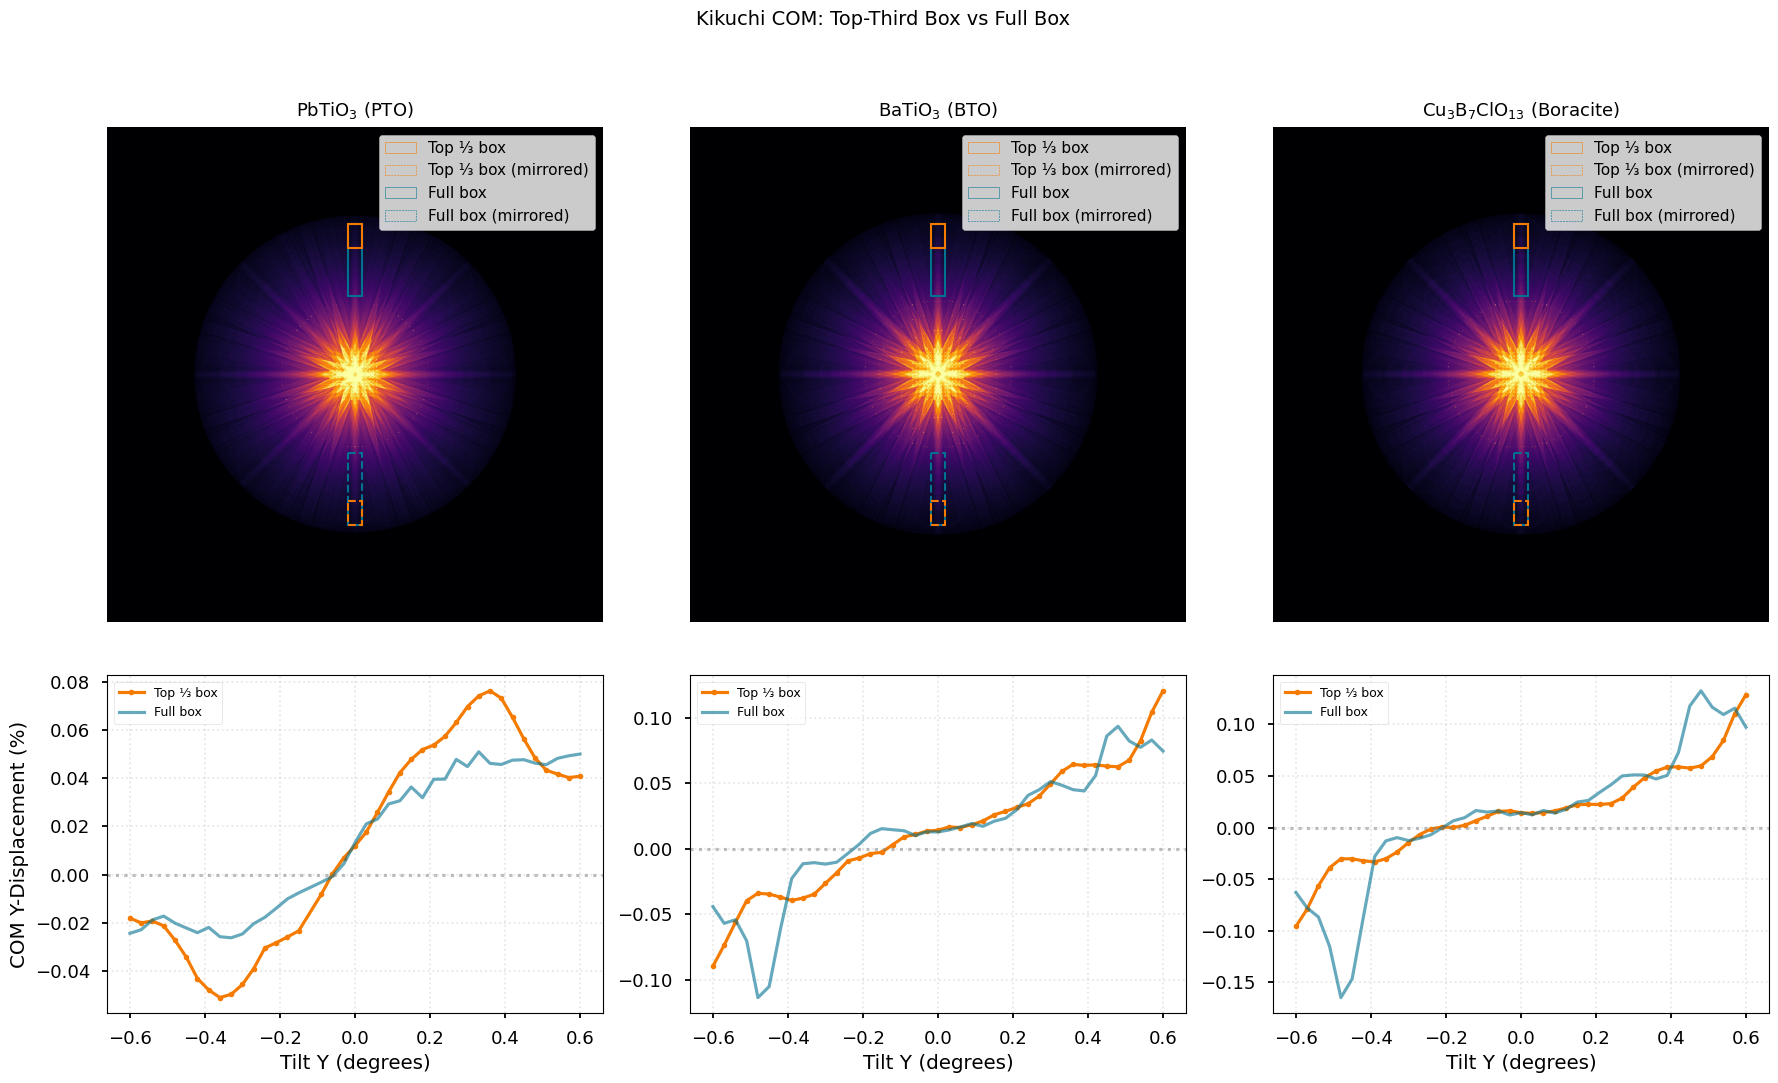

In [7]:
from matplotlib.patches import Rectangle

def draw_box(ax, box, color, linestyle='-'):
    (y_lo, y_hi), (x_lo, x_hi) = box
    ax.add_patch(Rectangle((x_lo, y_lo), x_hi - x_lo, y_hi - y_lo,
                            linewidth=1.5, edgecolor=color, facecolor='none',
                            linestyle=linestyle))

plt.style.use("seaborn-v0_8-talk")
fig, axes = plt.subplots(2, 3, figsize=(18, 11),
                         gridspec_kw={'height_ratios': [2, 1]})

for col, (name, res) in enumerate(results.items()):
    # ── Top row: diffraction pattern at 0° tilt with box overlay ──────────────
    ax_img = axes[0, col]
    img = np.asarray(res['zero_tilt_image'], dtype=np.float64)
    vmin, vmax = np.percentile(img, [0.5, 99.8])
    img_disp = np.clip((img - vmin) / (vmax - vmin + 1e-12), 0, 1) ** 0.5  # gamma=0.5
    ax_img.imshow(img_disp, cmap='inferno', origin='upper')

    draw_box(ax_img, res['full_box1'], C_FULL_BOX)
    draw_box(ax_img, res['full_box2'], C_FULL_BOX, linestyle='--')
    draw_box(ax_img, res['box1'], C_TOP_THIRD)
    draw_box(ax_img, res['box2'], C_TOP_THIRD, linestyle='--')

    ax_img.legend([
        Rectangle((0, 0), 1, 1, edgecolor=C_TOP_THIRD, facecolor='none', linestyle='-'),
        Rectangle((0, 0), 1, 1, edgecolor=C_TOP_THIRD, facecolor='none', linestyle='--'),
        Rectangle((0, 0), 1, 1, edgecolor=C_FULL_BOX, facecolor='none', linestyle='-'),
        Rectangle((0, 0), 1, 1, edgecolor=C_FULL_BOX, facecolor='none', linestyle='--'),
    ], ['Top ⅓ box', 'Top ⅓ box (mirrored)', 'Full box', 'Full box (mirrored)'], fontsize=11, loc='upper right')

    ax_img.set_title(MATERIALS[name]['label'], fontsize=13, pad=8)
    ax_img.axis('off')

    # ── Bottom row: COM vs tilt ────────────────────────────────────────────────
    ax = axes[1, col]
    ax.plot(res['tilt_clean'], res['com_top_third'],
            marker="o", markersize=4, label="Top ⅓ box", color=C_TOP_THIRD)
    ax.plot(res['tilt_all'], res['com_full_box'],
            marker="x", linestyle="-", label="Full box", color=C_FULL_BOX, alpha=0.6)
    ax.axhline(0, color="gray", linestyle=":", alpha=0.5)
    ax.set_xlabel("Tilt Y (degrees)")
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3, linestyle=":")

axes[1, 0].set_ylabel("COM Y-Displacement (%)")
fig.suptitle("Kikuchi COM: Top-Third Box vs Full Box", fontsize=14)
plt.tight_layout()
plt.show()
